# 4-fish recording 2024-10-23T15_18_28: each fish's gain (recorded / model) and a fit of $g_0 L^e$

One notebook per recording, all built by the same script (settings in the first code cell); the recordings are combined in
`EOD_gain_vs_length_4fish_combined.ipynb`. Four fish, all of them can emit. Here the emitter of an EOD is not known, so a few EODs per fish are chosen where it is clear who emitted,
and only those are used:

1. **Fish identity by size**: fish A (largest) … fish D (smallest). ZEUS labels keep their fish (they are ranked by the fish's median
   area); the tracker ids of the 2024-02-20T21_16_26 `.mgz` masks swap, so there the four masks are ranked by area in each frame.
2. **Lengths** with the rules of `fish_lengths.zeus_lengths` (as for the 2- and 3-fish recordings), on the size-ranked masks.
3. **Candidate EODs** of fish f: frame isolated for f (edge-to-edge distances of `Isolated_fish_frames.ipynb`, ≥ 1/4 of the tank side
   = 210 px from every other fish), all four masks pass the mask QC (the better-list rule, length 0.8–1.2 × median), and f's mask within
   `EL_MAX` of an electrode.
4. **Model** (my model, BEM conductivities: interior 100 × water, skin 0.05 × water over 0.005 cm; sink at the tail tip; unit current,
   no length scaling): for a sample of candidates, the pair voltages of each of the four fish as emitter, the other three as bodies.
5. **Well-predicted EODs**: fish f's model, sign fixed, and the recording, each scaled to max |v| = 1 (shape only, amplitude not used),
   match within `D_MAX`, and f matches better than every other fish by at least `MARGIN`. The `K` best per fish, at least 2 s apart.
6. **Gain** of each selected EOD: $a = r\cdot m_f/\lVert m_f\rVert^2$ (least squares, recorded volts per model unit), and as a check
   the ratio of the two max scalings, $\max|r|/\max|m_f|$. Fish gain = median over its EODs.
7. **Fit** $\log a_f = \log g_0 + e\,\log(L_f/L_\mathrm{ref})$ over the four fish ($L_\mathrm{ref}$ = geometric mean length), with
   bootstrap intervals (EODs resampled within each fish), the 4-point regression interval, and leave-one-fish-out.

The selection uses only shapes, so it does not favour any amplitude; all four fish are in one recording, so the amplifier gain and
the water are the same for all of them.

In [1]:
import os, pickle, json, time
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mask_metrics as mm
%matplotlib inline
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.ndimage import binary_dilation
from scipy.spatial import cKDTree
from scipy import stats
from compute_electric_field import theta_outer, multipole_sources, build_multipole_b, occupancy_field, unflatten_to_grid, gammas
from midline_methods import fish_midline_with_head
from eod_assign import load_electrode_pairs, peak_pattern, pair_voltages
import fish_lengths as fl

RECS = {   # masks; fish identity ('area_rank': rank the masks by area in each frame, 'zeus': ZEUS labels); nearest-fish distances
           # (Isolated_fish_frames.ipynb); EODs and their time column (s); electrode file
    '2024-02-20T21_16_26': dict(masks='results/isolated_frames/video2024-02-20T21_16_26_masks_cropped.pkl', identity='area_rank',
                                iso='results/isolated_frames/video2024-02-20T21_16_26_iso1-4_isolation.csv',
                                eod='data/Data_4fish_2024-02-20T21_16_26.csv', time='Time',
                                electrodes='data/electrodes/electrodes_signed_px_coord_4-fish.csv'),
    '2024-02-20T18_16_24': dict(masks='data/elephantnose_18_16_24_tracking_final.pkl', identity='zeus',
                                iso='results/isolated_frames/elephantnose_18_16_24_isolation.csv',
                                eod='data/track_Shiv/Group_01/Data_4fish_2024-02-20T18_16_24_no_ref_per.csv', time='RelativeTime',
                                electrodes='data/electrodes/electrodes_signed_px_coord_4-fish.csv'),
    '2024-10-23T15_18_28': dict(masks='data/elephantnose_2024-10-23_15_18_28_tracking_final.pkl', identity='zeus',
                                iso='results/isolated_frames/elephantnose_2024-10-23_15_18_28_isolation.csv',
                                eod='data/Data_4fish_2024-10-23T15_18_28.csv', time='Time',
                                electrodes='data/electrodes/electrodes_signed_px_coord_2024-10-23.csv',
                                iso_px=140),   # fish A, C and D are nearly always together here: at 210 px A has 42 isolated EODs, D 182

}
REC = '2024-10-23T15_18_28'
CFG = RECS[REC]
MASKS_PKL, ISO_CSV, EOD_CSV, ELECTRODES_CSV, TIME_COL = CFG['masks'], CFG['iso'], CFG['eod'], CFG['electrodes'], CFG['time']
K_OFFSET = 0           # mask frame = Frame + K_OFFSET: the head and tail keypoints stored in each EOD row lie on the masks of frame Frame
ISO_PX = CFG.get('iso_px', 210)   # isolated: >= 1/4 of the tank side (840 px) from every other fish, edge to edge (1/6 where set)
OUT = f'results/eod_gain_4fish/{REC}'
os.makedirs(f'{OUT}/figures', exist_ok=True)

FISH = (0, 1, 2, 3)
NAME = {0: 'fish A (largest)', 1: 'fish B', 2: 'fish C', 3: 'fish D (smallest)'}
COLOR = {0: '#C8361E', 1: '#E8A317', 2: '#2E8B57', 3: '#1F5FBF'}
PX_PER_CM = 912 / 60

# model: as the BEM run of EOD_assignment_3_fish_conductivities.ipynb, sink at the tail tip
N, n_poles, SINK = 150, 100, 0.0
h = 1.0 / (N - 1)
CELL_CM = (912 - 1) / (N - 1) / PX_PER_CM
SKIN_CM, LAMBDA_CM = 0.005, 1e-4 / 1e-3
MAT = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=100.0, eps_interior=0.0,
           sigma_skin=1 / (LAMBDA_CM / SKIN_CM + 1 / 100.0), eps_skin=0.0)
DELTA_H = SKIN_CM / CELL_CM
GAM = gammas(0.0, **MAT)

# selection
EL_MAX = 45            # px (3 cm): fish's mask to the nearest electrode
N_SAMPLE = 400         # candidates per fish solved with the model (at most one per second of the recording)
D_MAX = 0.30           # shape distance (max |v| = 1 patterns, L2 over 10 pairs) of the chosen fish
MARGIN = 0.30          # every other fish's shape distance is at least this much larger
K, MIN_GAP_S = 10, 2.0 # EODs per fish, at least MIN_GAP_S apart
N_WORKERS = 6

## 1. Masks and fish identity

Median mask area (px) of each tracker label per minute. With `identity = 'zeus'` each label keeps its fish and the labels are mapped
to A–D by their median area; label 4 (remnants) is dropped. With `'area_rank'` (2024-02-20T21_16_26, whose tracker ids 0 and 3 exchange
fish around minute 10) the four masks are ranked by area in each frame. Frames without exactly one mask of each of the four fish are
not used.

In [2]:
d = pickle.load(open(MASKS_PKL, 'rb'))
frames, P = d['frames'], d['shape'][0]; n_frames = len(frames)
assert P == 912 and sorted(frames) == list(range(n_frames))
area = pd.DataFrame([(k, l, a) for k in range(n_frames) for l, a in zip(frames[k]['labels'], frames[k]['areas'])], columns=['k', 'id', 'area'])
display(area.assign(minute=area.k // 3000).pivot_table(index='minute', columns='id', values='area', aggfunc='median')
        .rename(columns=lambda i: f'label {i}').round(0).T)

rank = np.full((n_frames, 4), -1)              # rank[k, tracker label] = fish (0 = A, largest); -1: frame not used
if CFG['identity'] == 'zeus':
    med_area = area[area.id.isin([0, 1, 2, 3])].groupby('id').area.median()
    LABEL2FISH = {int(l): r for r, l in enumerate(med_area.sort_values(ascending=False).index)}
    print('ZEUS label -> fish:', {l: NAME[f] for l, f in LABEL2FISH.items()})
for k in range(n_frames):
    labs = [l for l in frames[k]['labels'] if l in (0, 1, 2, 3)]
    if sorted(labs) != [0, 1, 2, 3]: continue
    if CFG['identity'] == 'zeus':
        for l in labs: rank[k, l] = LABEL2FISH[l]
    else:
        for r, i in enumerate(np.argsort([-a for a in frames[k]['areas']], kind='stable')): rank[k, frames[k]['labels'][i]] = r
def ranked_frame(k):
    fr = frames[k]
    if rank[k, 0] < 0: return dict(labels=[], boxes=[], masks=[], areas=[])
    keep = [j for j, l in enumerate(fr['labels']) if l in (0, 1, 2, 3)]
    return dict(labels=[int(rank[k, fr['labels'][j]]) for j in keep], boxes=[fr['boxes'][j] for j in keep],
                masks=[fr['masks'][j] for j in keep], areas=[fr['areas'][j] for j in keep])
ranked = dict(shape=d['shape'], frames={k: ranked_frame(k) for k in range(n_frames)})
print(f'frames with one mask of each fish: {(rank[:, 0] >= 0).sum()} / {n_frames}')

def crops(k):
    '''{fish: (box, bool crop)} of frame k (size-ranked), None if the frame does not have four masks.'''
    fr = ranked['frames'][k]
    return None if not fr['labels'] else {l: (b, mm.unpack_crop(p, b)) for l, p, b in zip(fr['labels'], fr['masks'], fr['boxes'])}

def frame_masks(k):
    m = np.zeros((4, P, P), bool)
    for l, ((y0, y1, x0, x1), c) in crops(k).items(): m[l, y0:y1, x0:x1] = c
    return m

minute,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
id,,,,,,,,,,,,,,,,,,,,
label 0,1325.0,1320.0,1341.0,1321.0,1308.0,1313.0,1347.0,1307.0,1300.0,1305.0,1320.0,1315.0,1290.0,1283.0,1296.0,1277.0,1305.0,1286.0,1306.0,1301.0
label 1,4582.0,4602.0,4848.0,4718.0,4709.0,4742.0,4806.0,4675.0,4716.0,4531.0,4626.0,4643.0,4556.0,4254.0,4744.0,4545.0,4534.0,4601.0,4752.0,4749.0
label 2,2939.0,2936.0,2860.0,2590.0,2558.0,2716.0,2778.0,2419.0,2677.0,2563.0,2672.0,2668.0,2758.0,2656.0,2682.0,2601.0,2654.0,2912.0,2749.0,3081.0
label 3,2172.0,2174.0,2247.0,2214.0,2309.0,2386.0,2226.0,2341.0,2309.0,2212.0,2238.0,2332.0,2285.0,2267.0,2296.0,2237.0,2362.0,2376.0,2420.0,2344.0


ZEUS label -> fish: {1: 'fish A (largest)', 2: 'fish B', 3: 'fish C', 0: 'fish D (smallest)'}


frames with one mask of each fish: 59519 / 60000


## 2. Lengths

`fish_lengths.zeus_lengths` on the size-ranked masks (every 5th frame; area within 10% of the fish's median, one piece, ≥ 10 px from the
image edge, ≥ 3 px from every other fish; the 300 most elongated; median midline length of the 30 straightest, ≤ 2.5 px from straight).

In [3]:
LEN = fl.zeus_lengths(ranked, list(FISH))
json.dump({'recording': REC, 'fish names': NAME, 'rules': 'fish_lengths.zeus_lengths on size-ranked masks', 'px_per_cm': PX_PER_CM,
           'fish': {str(f): v for f, v in LEN.items()}}, open(f'{OUT}/fish_lengths_4fish.json', 'w'), indent=1)
L_px = np.array([LEN[f]['L_px'] for f in FISH]); L_cm = L_px / PX_PER_CM
display(pd.DataFrame({'L (px)': L_px, 'L (cm)': L_cm, 'frames used': [LEN[f]['n_frames_used'] for f in FISH],
                      'range (px)': [LEN[f]['L_px_range'] for f in FISH], 'clean candidates': [LEN[f]['clean_candidates'] for f in FISH]},
                     index=[NAME[f] for f in FISH]).round(2))

,L (px),L (cm),frames used,range (px),clean candidates
fish A (largest),274.76,18.08,3,"[266.7, 278.1]",4011
fish B,196.08,12.90,22,"[194.36, 224.66]",6229
fish C,196.10,12.90,30,"[184.33, 199.38]",5829
fish D (smallest),131.08,8.62,30,"[122.96, 137.94]",5942


## 3. Candidate EODs: isolated, mask QC, near an electrode

Mask QC (as `EOD_assignment_3_fish_silent.ipynb`, with the better-list length rule), every one of the four fish, in the EOD's frame:
one piece (≥ 99%), area within 20% of the fish's median, principal-axis length 0.8–1.2 × median, not within 5 px of another fish, and
from the previous and the next frame a centroid step ≤ 15 px and an area change ≤ 15% (this also catches a change of the size ranking).
Medians from every 10th frame.

In [4]:
rows = []
for k in range(0, n_frames, 10):
    c = crops(k)
    if c is not None: rows += [dict(fish=s, **mm.shape_metrics(m, b)) for s, (b, m) in c.items()]
med = pd.DataFrame(rows).groupby('fish')[['px', 'major']].median()

AREA_TOL, LENGTH_RANGE, MIN_LARGEST_FRAC, MAX_STEP_PX, MAX_DAREA, CONTACT_GAP = 0.20, (0.8, 1.2), 0.99, 15, 0.15, 5
def in_contact(a, b, gap=CONTACT_GAP):
    (ba, ca), (bb, cb) = a, b
    if max(ba[0] - bb[1], bb[0] - ba[1], ba[2] - bb[3], bb[2] - ba[3]) > gap: return False
    y0, x0 = min(ba[0], bb[0]) - gap, min(ba[2], bb[2]) - gap
    win = np.zeros((2, max(ba[1], bb[1]) + gap - y0, max(ba[3], bb[3]) + gap - x0), bool)
    for w, ((r0, r1, c0, c1), c) in zip(win, (a, b)): w[r0 - y0:r1 - y0, c0 - x0:c1 - x0] = c
    return bool((binary_dilation(win[0], np.ones((3, 3)), iterations=gap) & win[1]).any())
_metr = {}
def metrics(k):
    if k not in _metr:
        c = crops(k) if 0 <= k < n_frames else None
        _metr[k] = None if c is None else {s: dict(mm.shape_metrics(m, b), contact=any(in_contact(c[s], c[o]) for o in c if o != s))
                                           for s, (b, m) in c.items()}
    return _metr[k]
def qc(k):
    m0, mp_, mn = metrics(k), metrics(k - 1), metrics(k + 1)
    if m0 is None or mp_ is None or mn is None: return False
    for s in FISH:
        q = m0[s]
        if abs(q['px'] / med.px[s] - 1) > AREA_TOL or not LENGTH_RANGE[0] <= q['major'] / med.major[s] <= LENGTH_RANGE[1]: return False
        if q['largest_frac'] < MIN_LARGEST_FRAC or q['contact']: return False
        if any(np.hypot(q['cx'] - o['cx'], q['cy'] - o['cy']) > MAX_STEP_PX or abs(q['px'] / o['px'] - 1) > MAX_DAREA for o in (mp_[s], mn[s])):
            return False
    return True

df_eod = pd.read_csv(EOD_CSV)
iso = pd.read_csv(ISO_CSV).set_index('frame')
el = pd.read_csv(ELECTRODES_CSV)
el_pts = np.unique(np.r_[el[['y1', 'x1']].to_numpy(), el[['y2', 'x2']].to_numpy()], axis=0)   # (row, col) px
el_tree = cKDTree(el_pts)
cand = []
for i, k in zip(df_eod.index, df_eod.Frame + K_OFFSET):
    if k not in iso.index or not iso.at[k, 'all_tracked'] or not 0 <= k < n_frames or rank[k, 0] < 0: continue
    cand += [(i, k, int(rank[k, l])) for l in range(4) if iso.at[k, f'nearest_px_{l}'] >= ISO_PX]
C = pd.DataFrame(cand, columns=['row', 'frame', 'fish'])
n_iso = C.fish.value_counts().sort_index()
C = C[C.frame.map({k: qc(k) for k in C.frame.unique()})].copy()
n_qc = C.fish.value_counts().sort_index()
def el_dist(k, s):
    (y0, y1, x0, x1), m = crops(k)[s]
    return el_tree.query(np.argwhere(m) + (y0, x0))[0].min()
C['el_dist_px'] = [el_dist(k, s) for k, s in zip(C.frame, C.fish)]
C['time'] = df_eod[TIME_COL].to_numpy(float)[C.row]
display(pd.DataFrame({'isolated': n_iso, 'and mask QC': n_qc, f'and ≤ {EL_MAX} px from an electrode': C[C.el_dist_px <= EL_MAX].fish.value_counts().sort_index()},
                     ).rename(index=NAME).rename_axis('EODs'))
C.to_csv(f'{OUT}/candidate_eods.csv', index=False)

,isolated,and mask QC,and ≤ 45 px from an electrode
EODs,,,
fish A (largest),624,318,1.0
fish B,85454,26607,16880.0
fish C,7369,1880,1056.0
fish D (smallest),1593,447,NaN


## 4. Model voltages of a sample of candidates

Per fish, at most one candidate per second of the recording (so the sample covers many visits), then `N_SAMPLE` of those at random.
For each sampled EOD, each of the four fish is the emitter in turn (unit current), the other three are bodies.

In [5]:
rng = np.random.default_rng(0)
near = C[C.el_dist_px <= EL_MAX]
S = (near.assign(sec=np.floor(near.time)).groupby(['fish', 'sec'], group_keys=False).apply(lambda g: g.sample(1, random_state=rng))
     .groupby('fish', group_keys=False).apply(lambda g: g.sample(min(N_SAMPLE, len(g)), random_state=rng)).reset_index(drop=True))
print('sampled per fish:', S.fish.value_counts().sort_index().rename(index=NAME).to_dict())

pairs = load_electrode_pairs(ELECTRODES_CSV, P); pair_ids = [p for p, _, _ in pairs]
cols = {p: [f'electrode_{p}_time_{t}' for t in range(1, 26)] for p in pair_ids}

def recorded(i):
    V = np.stack([df_eod.loc[i, cols[p]].to_numpy(float) for p in pair_ids])
    return peak_pattern(V - V.mean(axis=1, keepdims=True))[0]

def build_A_fast(occ, N, delta_h, g_water, g_skin, g_interior):
    '''build_A_shell, vectorized (as EOD_assignment_3_fish_conductivities.ipynb, checked there entry for entry).'''
    tx, ty = theta_outer(occ)
    gnode = np.where(occ > 0.5, g_interior, g_water).astype(complex)
    skin = delta_h * (1 / g_skin - 1 / g_interior)
    def w(gC, gM, thc):
        with np.errstate(invalid='ignore'):
            return np.where(np.isnan(thc), gC, 1.0 / (thc / gC + (1 - thc) / gM + skin))
    k = np.arange(N * N).reshape(N, N)
    W = {'up': w(gnode[1:, :], gnode[:-1, :], 1 - tx), 'down': w(gnode[:-1, :], gnode[1:, :], tx),
         'left': w(gnode[:, 1:], gnode[:, :-1], 1 - ty), 'right': w(gnode[:, :-1], gnode[:, 1:], ty)}
    src = {'up': k[1:, :], 'down': k[:-1, :], 'left': k[:, 1:], 'right': k[:, :-1]}
    dst = {'up': k[:-1, :], 'down': k[1:, :], 'left': k[:, :-1], 'right': k[:, 1:]}
    full = {dd: np.zeros((N, N), complex) for dd in W}
    full['up'][1:, :], full['down'][:-1, :] = W['up'], W['down']
    full['left'][:, 1:], full['right'][:, :-1] = W['left'], W['right']
    ws = ((0j + full['up']) + full['down']) + full['left'] + full['right']
    r = np.concatenate([src[dd].ravel() for dd in W] + [k.ravel()])
    c = np.concatenate([dst[dd].ravel() for dd in W] + [k.ravel()])
    v = np.concatenate([W[dd].ravel() for dd in W] + [-ws.ravel()])
    return sp.coo_matrix((v, (r, c)), shape=(N * N, N * N), dtype=complex).tocsr()

def solve(A, b, pin=0):
    '''solve_potential (pinned node, zero-mean gauge), real arithmetic (omega = 0).'''
    M = (-A).tocsr().real
    keep = np.ones(M.shape[0]); keep[pin] = 0
    M = (sp.diags(keep) @ M + sp.csr_matrix(([1.0], ([pin], [pin])), shape=M.shape)).tocsc()
    rhs = np.asarray(b).ravel().real.copy(); rhs[pin] = 0
    phi = splu(M).solve(rhs); return phi - phi.mean()

def model_voltages(i):
    '''EOD row i -> unit-current pair voltages (4, n_pairs) of each fish as the emitter (NaN if its midline fails).'''
    fm = frame_masks(int(df_eod.Frame[i]) + K_OFFSET)
    u = np.full((4, len(pairs)), np.nan)
    for f in FISH:
        try:
            mid = fish_midline_with_head(fm[f], n_ctrl=n_poles + 1)['midline']
        except Exception:
            continue
        if mid is None or not np.isfinite(mid).all(): continue
        b = build_multipole_b(*multipole_sources(mid, I0=1.0, sink_frac=SINK), h, N)
        u[f] = pair_voltages(unflatten_to_grid(solve(build_A_fast(occupancy_field(fm, N, skip=f), N, DELTA_H, *GAM), b), N).real, pairs, N)
    return i, u

CACHE = f'{OUT}/model_voltages_N{N}_sink0_bem_sample.pkl'
cache = pd.read_pickle(CACHE) if os.path.exists(CACHE) else {}
todo = sorted(set(S.row) - set(cache))
t0 = time.time()
with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as pool:
    for i, u in pool.map(model_voltages, todo, chunksize=4): cache[i] = u
pd.to_pickle(cache, CACHE)
print(f'{len(todo)} EODs solved in {time.time() - t0:.0f} s; {len(cache)} cached')

sampled per fish: {'fish A (largest)': 1, 'fish B': 400, 'fish C': 41}


/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_25876/3184628704.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  S = (near.assign(sec=np.floor(near.time)).groupby(['fish', 'sec'], group_keys=False).apply(lambda g: g.sample(1, random_state=rng))
/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_25876/3184628704.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby('fish', group_keys=Fals

353 EODs solved in 20 s; 3011 cached


## 5. Sign, shape distances and the well-predicted EODs

The sign of the model relative to the recording is checked on the sample (fish f's model against the recording, for the EODs where f
is the best shape match with either sign); the 3-fish recording needed × −1. Then, per pair, how often the recorded sign agrees with
the sign-fixed model on those EODs, where the model's pair voltage is at least 0.3 × its max (a pair wired the other way round would
agree in few EODs).

In [6]:
R = np.stack([recorded(i) for i in S.row])                                    # (n, 10) volts
U = np.stack([cache[i] for i in S.row])                                       # (n, 4, 10)
f_ = S.fish.to_numpy(); n = len(S)
unit = lambda x: x / np.abs(x).max(axis=-1, keepdims=True)
dist = lambda sign: np.linalg.norm(sign * unit(U) - unit(R)[:, None], axis=2)  # (n, 4)
Dp, Dm = dist(+1), dist(-1)
best_any = np.minimum(Dp, Dm)
own_best = np.nanargmin(np.where(np.isfinite(best_any), best_any, np.inf), axis=1) == f_
neg = Dm[np.arange(n), f_] < Dp[np.arange(n), f_]
print(f'EODs where the isolated fish is the best match (either sign): {own_best.sum()} / {n}; of these, model x -1 fits better in '
      f'{100 * neg[own_best].mean():.1f}%')
SIGN = -1 if neg[own_best].mean() > 0.5 else 1
M = SIGN * U                                                                    # model, sign fixed
D = dist(SIGN); D = np.where(np.isfinite(D), D, np.inf)
agree = np.where(np.abs(M[np.arange(n), f_]) >= 0.3 * np.abs(M[np.arange(n), f_]).max(1, keepdims=True),
                 np.sign(R) == np.sign(M[np.arange(n), f_]), np.nan)[own_best]
display(pd.DataFrame({'% EODs where the recorded sign agrees': 100 * np.nanmean(agree, 0), 'n EODs': np.isfinite(agree).sum(0)},
                     index=pd.Index(pair_ids, name='pair')).round(1).T)
S['d_own'] = D[np.arange(n), f_]
S['d_other'] = np.min(np.where(np.arange(4)[None] == f_[:, None], np.inf, D), axis=1)
S['gain_ls'] = np.einsum('np,np->n', R, M[np.arange(n), f_]) / np.einsum('np,np->n', M[np.arange(n), f_], M[np.arange(n), f_])
S['gain_peak'] = np.abs(R).max(1) / np.abs(M[np.arange(n), f_]).max(1)
S['pair_max'] = np.array(pair_ids)[np.abs(R).argmax(1)]
S.to_csv(f'{OUT}/sampled_eods.csv', index=False)

def choose(S, d_max=D_MAX, margin=MARGIN, k=K, gap=MIN_GAP_S, el_max=EL_MAX):
    '''The k EODs per fish with the smallest own shape distance among those passing d_max and margin, >= gap seconds apart.'''
    ok = S[(S.d_own <= d_max) & (S.d_other - S.d_own >= margin) & (S.el_dist_px <= el_max)].sort_values('d_own')
    out = []
    for f, g in ok.groupby('fish'):
        t = []
        for r in g.itertuples():
            if all(abs(r.time - x) >= gap for x in t): t.append(r.time); out.append(r.Index)
            if len(t) == k: break
    return S.loc[out]

SEL = choose(S)
display(pd.DataFrame({'sampled': S.fish.value_counts(), 'pass D_MAX and MARGIN': S[(S.d_own <= D_MAX) & (S.d_other - S.d_own >= MARGIN)].fish.value_counts(),
                      'chosen': SEL.fish.value_counts()}).sort_index().fillna(0).astype(int).rename(index=NAME))
SEL.to_csv(f'{OUT}/selected_eods.csv', index=False)
display(SEL[['fish', 'row', 'frame', 'time', 'el_dist_px', 'pair_max', 'd_own', 'd_other', 'gain_ls', 'gain_peak']].round(4))

EODs where the isolated fish is the best match (either sign): 68 / 442; of these, model x -1 fits better in 94.1%


/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_25876/2174792070.py:17: RuntimeWarning: Mean of empty slice
  display(pd.DataFrame({'% EODs where the recorded sign agrees': 100 * np.nanmean(agree, 0), 'n EODs': np.isfinite(agree).sum(0)},


pair,1,2,3,4,5,6,7,8,9,10
% EODs where the recorded sign agrees,80.0,NaN,NaN,100.0,100.0,96.4,95.0,75.0,90.9,96.7
n EODs,5.0,0.0,0.0,2.0,4.0,56.0,60.0,12.0,11.0,61.0


,sampled,pass D_MAX and MARGIN,chosen
fish,,,
fish A (largest),1,0,0
fish B,400,48,10
fish C,41,6,4


,fish,row,frame,time,el_dist_px,pair_max,d_own,d_other,gain_ls,gain_peak
5,1,108950,50832,1016.6399,21.5407,7,0.0469,1.4591,0.7872,0.7863
202,1,90105,42081,841.6290,27.4591,7,0.0471,1.6648,0.8253,0.8262
278,1,122289,57109,1142.1883,36.7967,7,0.0553,1.9185,0.7393,0.7364
276,1,76581,35792,715.8415,39.2046,7,0.0569,1.3178,0.8796,0.8879
393,1,19504,8508,170.1566,33.6006,7,0.0583,1.4349,0.8292,0.8394
172,1,118482,55333,1106.6545,40.4969,7,0.0585,1.3091,0.9663,0.9660
307,1,34723,15441,308.8115,29.0689,7,0.0588,1.4225,0.8150,0.8297
163,1,83299,38806,776.1263,32.2025,7,0.0597,1.8097,0.8665,0.8786
381,1,36820,16401,328.0121,29.0000,7,0.0607,1.7423,0.9139,0.9190
66,1,108679,50673,1013.4691,25.4951,7,0.0623,1.2578,0.9643,0.9604


## 6. The chosen EODs

For each fish, its best EOD and its worst chosen EOD (largest shape distance): the masks (the emitter filled, the others as outlines)
with the electrodes, and the 10 pair voltages: recorded, and the model scaled by that EOD's own gain $a$.

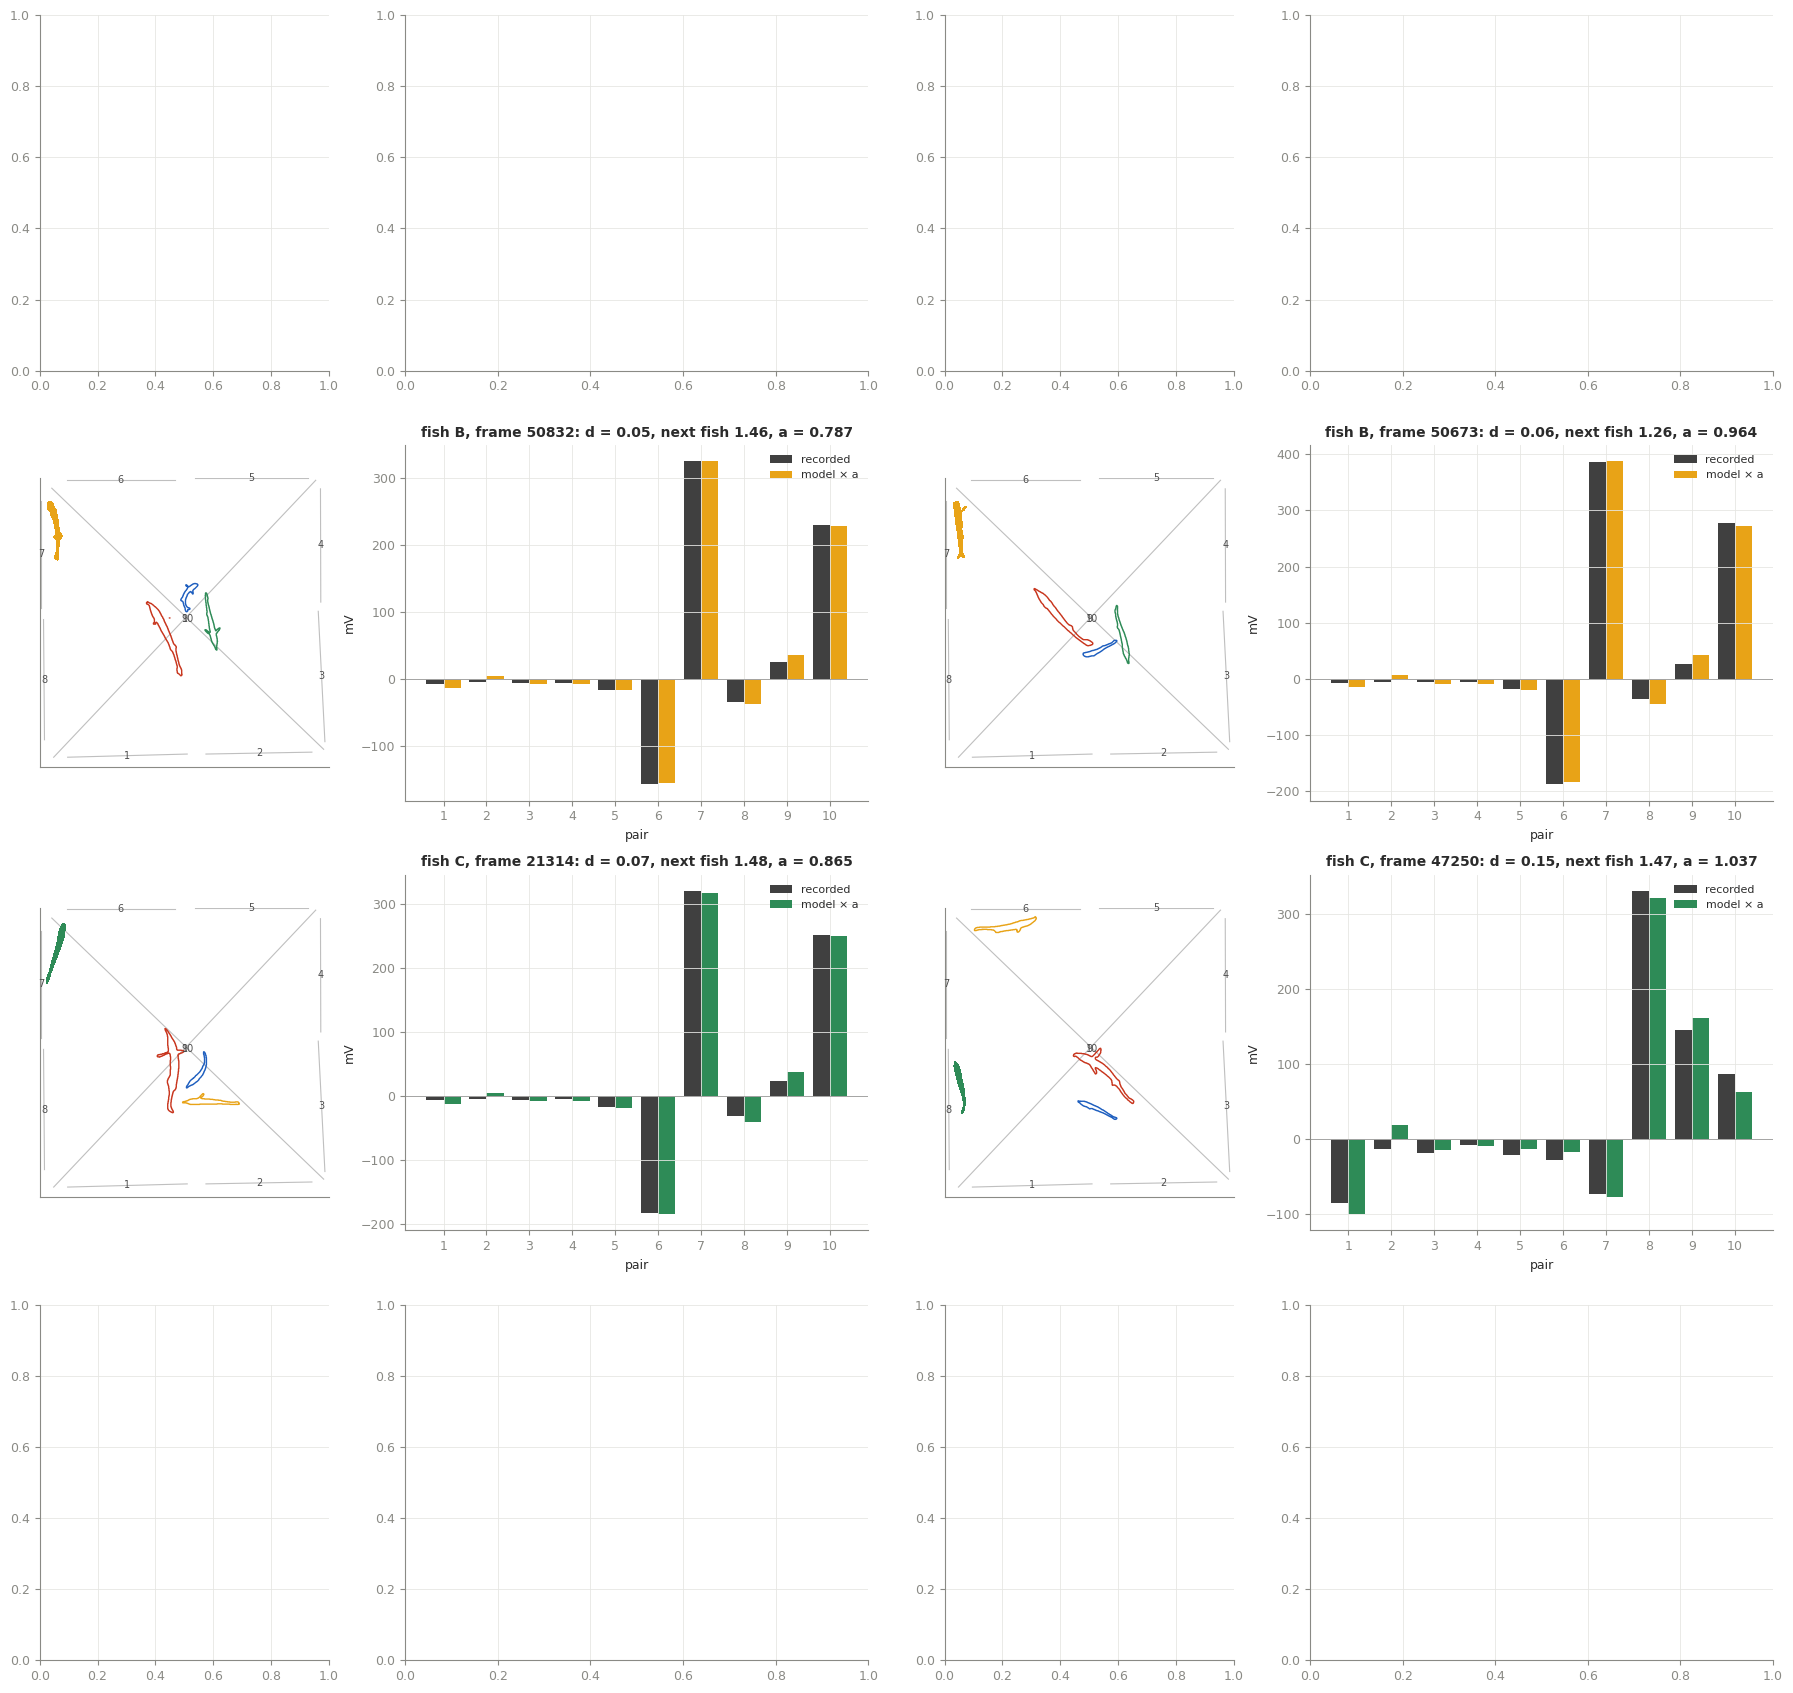

In [7]:
def show(ax_map, ax_bar, r):
    fm = frame_masks(int(r.frame)); f = int(r.fish)
    for s in FISH:
        if s == f: ax_map.contourf(fm[s], levels=[0.5, 1], colors=[COLOR[s]])
        else: ax_map.contour(fm[s], levels=[0.5], colors=[COLOR[s]], linewidths=1)
    for e in el.itertuples():
        ax_map.plot([e.x1, e.x2], [e.y1, e.y2], color='0.75', lw=0.8, zorder=0)
        ax_map.text((e.x1 + e.x2) / 2, (e.y1 + e.y2) / 2, e.pair, fontsize=7, ha='center', va='center', color='0.3')
    ax_map.set(xlim=(0, P), ylim=(P, 0), aspect='equal', xticks=[], yticks=[])
    j = list(S.index).index(r.Index)
    x = np.arange(len(pair_ids))
    ax_bar.bar(x - 0.2, 1e3 * R[j], 0.4, color='0.25', label='recorded')
    ax_bar.bar(x + 0.2, 1e3 * r.gain_ls * M[j, f], 0.4, color=COLOR[f], label='model × a')
    ax_bar.set(xticks=x, xticklabels=pair_ids, xlabel='pair', ylabel='mV',
               title=f'{NAME[f]}, frame {int(r.frame)}: d = {r.d_own:.2f}, next fish {r.d_other:.2f}, a = {r.gain_ls:.3f}')
    ax_bar.axhline(0, color='0.6', lw=0.6); ax_bar.legend(fontsize=8, frameon=False)

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
fig, axs = plt.subplots(4, 4, figsize=(18, 17), gridspec_kw=dict(width_ratios=[1, 1.6, 1, 1.6]))
for f in FISH:
    g = SEL[SEL.fish == f].sort_values('d_own')
    for c, r in enumerate([next(g.head(1).itertuples()), next(g.tail(1).itertuples())] if len(g) else []):
        show(axs[f, 2 * c], axs[f, 2 * c + 1], r)
plt.tight_layout(); fig.savefig(f'{OUT}/figures/chosen_eods_examples.png', dpi=100); plt.show()

## 7. Gain per fish and the fit of $g_0 L^e$

In [8]:
Lref = np.exp(np.log(L_cm).mean())
def fit(sel, col='gain_ls'):
    '''Slope e and g0 (at Lref) of log(median gain per fish) on log(L / Lref), the four fish weighted equally.'''
    gm = sel.groupby('fish')[col].median().reindex(FISH)
    x, y = np.log(L_cm / Lref), np.log(gm.to_numpy())
    ok = np.isfinite(y); e, c = np.polyfit(x[ok], y[ok], 1)
    return e, np.exp(c), gm

def boot(sel, col='gain_ls', n_boot=2000, seed=1):
    rng = np.random.default_rng(seed); es = []
    groups = [g for _, g in sel.groupby('fish')]
    for _ in range(n_boot):
        es.append(fit(pd.concat([g.sample(len(g), replace=True, random_state=rng) for g in groups]), col)[0])
    return np.percentile(es, [2.5, 97.5])

assert (SEL.gain_ls > 0).all()
e_ls, g0_ls, gm = fit(SEL)
x, y = np.log(L_cm / Lref), np.log(gm.to_numpy())
reg = stats.linregress(x, y); tq = stats.t.ppf(0.975, len(x) - 2)
tab = pd.DataFrame({'L (cm)': L_cm, 'n EODs': SEL.groupby('fish').size().reindex(FISH).to_numpy(),
                    'median gain a (V / model unit)': gm.to_numpy(),
                    'IQR low': SEL.groupby('fish').gain_ls.quantile(0.25).reindex(FISH).to_numpy(),
                    'IQR high': SEL.groupby('fish').gain_ls.quantile(0.75).reindex(FISH).to_numpy(),
                    'median peak ratio': SEL.groupby('fish').gain_peak.median().reindex(FISH).to_numpy(),
                    'fit g0 (L / Lref)^e': g0_ls * (L_cm / Lref) ** e_ls}, index=[NAME[f] for f in FISH])
tab.to_csv(f'{OUT}/gain_per_fish.csv'); display(tab.round(4))

res = {'least-squares gain': (e_ls, *boot(SEL), reg.slope - tq * reg.stderr, reg.slope + tq * reg.stderr, reg.rvalue ** 2, g0_ls)}
e_pk, g0_pk, gpk = fit(SEL, 'gain_peak'); reg_pk = stats.linregress(x, np.log(gpk.to_numpy()))
res['peak ratio (max |r| / max |m|)'] = (e_pk, *boot(SEL, 'gain_peak'), reg_pk.slope - tq * reg_pk.stderr, reg_pk.slope + tq * reg_pk.stderr,
                                         reg_pk.rvalue ** 2, g0_pk)
FIT = pd.DataFrame(res, index=['e', 'bootstrap 2.5%', 'bootstrap 97.5%', '4-point regression 2.5%', '4-point regression 97.5%', 'R²',
                               f'g0 at L = {Lref:.2f} cm']).T
FIT.to_csv(f'{OUT}/fit_g0_L_e.csv'); display(FIT.round(3))

loo = {f'without {NAME[f]}': np.polyfit(np.delete(x, f), np.delete(y, f), 1)[0] for f in FISH}
display(pd.Series(loo, name='e, leave one fish out').round(3))

,L (cm),n EODs,median gain a (V / model unit),IQR low,IQR high,median peak ratio,fit g0 (L / Lref)^e
fish A (largest),18.0763,NaN,NaN,NaN,NaN,NaN,2.508576e+143
fish B,12.9000,10.0,0.8478,0.8176,0.9053,0.859,8.478000e-01
fish C,12.9015,4.0,0.9510,0.8538,1.0773,0.971,9.510000e-01
fish D (smallest),8.6238,NaN,NaN,NaN,NaN,NaN,0.000000e+00


,e,bootstrap 2.5%,bootstrap 97.5%,4-point regression 2.5%,4-point regression 97.5%,R²,g0 at L = 12.69 cm
least-squares gain,979.190,-534.205,2948.417,NaN,NaN,NaN,0.0
peak ratio (max |r| / max |m|),1045.214,-593.000,2826.792,NaN,NaN,NaN,0.0


without fish A (largest)    NaN
without fish B              NaN
without fish C              NaN
without fish D (smallest)   NaN
Name: e, leave one fish out, dtype: float64

### Sensitivity to the selection

In [9]:
sens = []
for el_max in (15, 30, 45):
    for d_max in (0.2, 0.3, 0.4):
        for k in (5, 10, 20):
            sel = choose(S, d_max=d_max, k=k, el_max=el_max)
            nf = sel.groupby('fish').size().reindex(FISH).fillna(0).astype(int)
            e = fit(sel)[0] if (nf > 0).all() else np.nan
            sens.append({'EL_MAX (px)': el_max, 'D_MAX': d_max, 'K': k, 'EODs per fish (A, B, C, D)': tuple(nf), 'e': e})
sens = pd.DataFrame(sens); sens.to_csv(f'{OUT}/fit_sensitivity.csv', index=False)
display(sens.round(3))
print(f"e over all {sens.e.notna().sum()} settings: median {sens.e.median():.2f}, range {sens.e.min():.2f} to {sens.e.max():.2f}")

,EL_MAX (px),D_MAX,K,"EODs per fish (A, B, C, D)",e
0,15,0.2,5,"(0, 0, 0, 0)",NaN
1,15,0.2,10,"(0, 0, 0, 0)",NaN
2,15,0.2,20,"(0, 0, 0, 0)",NaN
3,15,0.3,5,"(0, 0, 0, 0)",NaN
4,15,0.3,10,"(0, 0, 0, 0)",NaN
5,15,0.3,20,"(0, 0, 0, 0)",NaN
6,15,0.4,5,"(0, 0, 0, 0)",NaN
7,15,0.4,10,"(0, 0, 0, 0)",NaN
8,15,0.4,20,"(0, 0, 0, 0)",NaN
9,30,0.2,5,"(0, 5, 1, 0)",NaN


e over all 0 settings: median nan, range nan to nan


/Users/lencacuturela/opt/anaconda3/envs/electric_fish/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


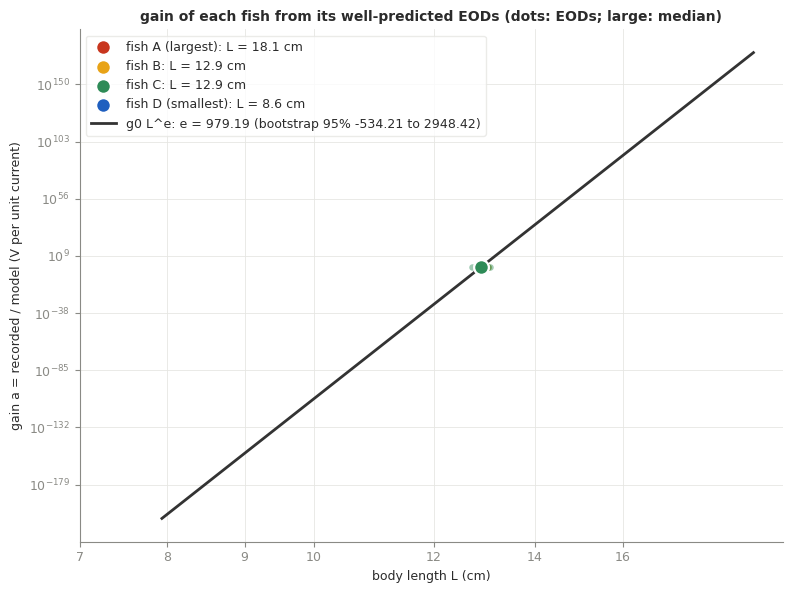

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
for f in FISH:
    g = SEL[SEL.fish == f]
    ax.scatter(np.full(len(g), L_cm[f]) * np.exp(rng.normal(0, 0.008, len(g))), g.gain_ls, s=22, color=COLOR[f], alpha=0.45, lw=0)
    ax.scatter(L_cm[f], gm[f], s=110, color=COLOR[f], edgecolor='white', lw=1.5, zorder=3, label=f'{NAME[f]}: L = {L_cm[f]:.1f} cm')
xx = np.linspace(L_cm.min() * 0.92, L_cm.max() * 1.08, 50)
lo, hi = FIT.loc['least-squares gain', ['bootstrap 2.5%', 'bootstrap 97.5%']]
ax.plot(xx, g0_ls * (xx / Lref) ** e_ls, color='0.2', lw=2, label=f'g0 L^e: e = {e_ls:.2f} (bootstrap 95% {lo:.2f} to {hi:.2f})')
ax.set(xscale='log', yscale='log', xlabel='body length L (cm)', ylabel='gain a = recorded / model (V per unit current)',
       title='gain of each fish from its well-predicted EODs (dots: EODs; large: median)')
ax.set_xticks([7, 8, 9, 10, 12, 14, 16]); ax.set_xticklabels([7, 8, 9, 10, 12, 14, 16]); ax.minorticks_off()
ax.legend(fontsize=9, loc='upper left', frameon=True, facecolor='white', edgecolor='#e6e6e3')
ax.grid(True, color='#e6e6e3')
plt.tight_layout(); fig.savefig(f'{OUT}/figures/gain_vs_length.png', dpi=130); plt.show()

## 8. The gain depends on where the fish is

Below: the median gain by fish and by the pair with the largest recorded voltage (the pair the fish is nearest), over all sampled EODs
passing D_MAX = 0.4 and the margin. The same breakdown on the two controls with a known emitter (better list, emitter's model, sign
fixed, shape distance ≤ 0.3) shows the same kind of pattern: the gain is lower near pairs 1–4 than near pairs 6–8. So part of the
difference between fish is where they were, not who they are: fish B was mostly near pairs 1–3, fish C near 6, 7 and 10.

Check: each EOD's gain divided by a control's relative gain at its pair (control median per pair / median over pairs; no 4-fish
amplitude is used), then the same fit.

In [11]:
ok4 = S[(S.d_own <= 0.4) & (S.d_other - S.d_own >= MARGIN)]
display(ok4.pivot_table(index='pair_max', columns='fish', values='gain_ls', aggfunc=['median', 'size']).rename(columns=NAME).round(3))

def control_profile(res, cache, em, better):
    c = pd.read_pickle(f'{res}/{cache}')
    Rc = np.stack(c.v_rec.map(np.asarray)); Mc = -np.stack(c.u_sink0.map(lambda u: np.asarray(u, float)))[:, em]
    k = np.isfinite(Mc).all(1) & c.frame.isin(pd.read_csv(better).frame).to_numpy(); Rc, Mc = Rc[k], Mc[k]
    a = (Rc * Mc).sum(1) / (Mc * Mc).sum(1)
    dd = np.linalg.norm(unit(Rc) - unit(Mc), axis=1)
    t = pd.DataFrame({'pair_max': np.array(pair_ids)[np.abs(Rc).argmax(1)], 'a': a})[dd <= 0.3]
    s = t.groupby('pair_max').a.median()
    return s / s.median(), t.groupby('pair_max').size()
PROF = {'2-fish control': control_profile('results/eod_ground_truth/conductivities', 'model_voltages_N150_sinks0and0.05_el46ee63_bem_a453a8.pkl', 1,
                                          'results/eod_ground_truth/good_frames_better_list.csv'),
        '3-fish control': control_profile('results/eod_ground_truth_3fish/conductivities', 'model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl', 0,
                                          'results/eod_ground_truth_3fish/good_frames_better_list.csv')}
display(pd.concat({f'{k}: relative gain': v[0] for k, v in PROF.items()} | {f'{k}: n EODs': v[1] for k, v in PROF.items()}, axis=1).round(2))

rows = {}
for lab, sel in [(f'chosen (K = {K}, D_MAX = {D_MAX})', SEL), ('all sampled passing D_MAX = 0.4 and the margin', ok4)]:
    for pn in ['no correction', *PROF]:
        s = sel.copy()
        if pn != 'no correction': s['gain_ls'] = s.gain_ls / s.pair_max.map(PROF[pn][0])
        e, g0, gmed = fit(s); r = stats.linregress(x, np.log(gmed.to_numpy()))
        rows[(lab, pn)] = {**{f'gain {NAME[f]}': gmed[f] for f in FISH}, 'max / min gain': gmed.max() / gmed.min(), 'e': e,
                           'SE (4 points)': r.stderr, 'bootstrap 2.5%': boot(s)[0], 'bootstrap 97.5%': boot(s)[1], 'R²': r.rvalue ** 2}
CORR = pd.DataFrame(rows).T; CORR.to_csv(f'{OUT}/fit_with_location_correction.csv'); display(CORR.round(3))

median          size       
fish     fish B fish C fish B fish C
pair_max                            
5         0.629    NaN    2.0    NaN
6         0.882    NaN   10.0    NaN
7         0.835  0.843   37.0    4.0
8         0.737  1.118    4.0    2.0

,2-fish control: relative gain,3-fish control: relative gain,2-fish control: n EODs,3-fish control: n EODs
pair_max,,,,
1,0.92,0.83,117,46.0
2,0.75,NaN,61,NaN
3,0.78,1.24,29,2.0
4,0.80,0.80,58,9.0
5,0.97,1.00,12,21.0
6,1.40,1.00,347,35.0
7,1.26,1.21,389,203.0
8,1.06,1.13,231,81.0
9,1.03,0.86,154,392.0


gain fish A (largest)  \
chosen (K = 10, D_MAX = 0.3)                   no correction                     NaN   
                                               2-fish control                    NaN   
                                               3-fish control                    NaN   
all sampled passing D_MAX = 0.4 and the margin no correction                     NaN   
                                               2-fish control                    NaN   
                                               3-fish control                    NaN   

                                                               gain fish B  \
chosen (K = 10, D_MAX = 0.3)                   no correction         0.848   
                                               2-fish control        0.674   
                                               3-fish control        0.701   
all sampled passing D_MAX = 0.4 and the margin no correction         0.831   
                                               2-fish control        0.664   
                                               3-fish control        0.716   

                                                               gain fish C  \
chosen (K = 10, D_MAX = 0.3)                   no correction         0.951   
                                               2-fish control        0.831   
                                               3-fish control        0.814   
all sampled passing D_MAX = 0.4 and the margin no correction         0.872   
                                               2-fish control        0.693   
                                               3-fish control        0.721   

                                                               gain fish D (smallest)  \
chosen (K = 10, D_MAX = 0.3)                   no correction                      NaN   
                                               2-fish control                     NaN   
                                               3-fish control                     NaN   
all sampled passing D_MAX = 0.4 and the margin no correction                      NaN   
                                               2-fish control                     NaN   
                                               3-fish control                     NaN   

                                                               max / min gain  \
chosen (K = 10, D_MAX = 0.3)                   no correction            1.122   
                                               2-fish control           1.233   
                                               3-fish control           1.162   
all sampled passing D_MAX = 0.4 and the margin no correction            1.050   
                                               2-fish control           1.045   
                                               3-fish control           1.007   

                                                                      e  \
chosen (K = 10, D_MAX = 0.3)                   no correction    979.190   
                                               2-fish control  1785.284   
                                               3-fish control  1280.016   
all sampled passing D_MAX = 0.4 and the margin no correction    418.675   
                                               2-fish control   375.543   
                                               3-fish control    57.276   

                                                               SE (4 points)  \
chosen (K = 10, D_MAX = 0.3)                   no correction             NaN   
                                               2-fish control            NaN   
                                               3-fish control            NaN   
all sampled passing D_MAX = 0.4 and the margin no correction             NaN   
                                               2-fish control            NaN   
                                               3-fish control            NaN   

                                                               bootstrap 

## 9. Fish compared at the same spot

To cancel the location effect, each fish's gain is compared with another fish's gain **at the same spot**: two isolated, mask-QC EODs
(any distance from the electrodes) of two different fish whose centroids are within `POS_TOL` px and whose headings (tail → head,
the bulkier half is the head, as `Isolated_fish_frames.ipynb`) are within `ANGLE_TOL`°. The same electrodes see the two fish from the
same place, so a channel's gain or a location-dependent model error cancels in the ratio $a_f/a_g$, and
$\log(a_f/a_g) = e\,\log(L_f/L_g)$ + individual differences.

- Visits: a fish's candidate EODs split where more than 1 s passes without one. For each pair of visits (one per fish), the
  `MATCH_PER_VISIT` closest EOD pairs are solved (all four fish as emitter).
- Kept when both EODs are clearly their fish's (shape distance ≤ `D_MAX`, every other fish ≥ `MARGIN` worse), then the closest kept
  match per pair of visits.
- **e from the ratios**: the slope through the origin of $\log(a_f/a_g)$ on $\log(L_f/L_g)$ over all matches (bootstrap over pairs of
  visits). This assumes the fish differ only by length.
- **Gain per fish without the location effect**: fish effects $\alpha_f$ fitted to the log ratios (least squares, mean 0), then
  regressed on $\log L$: the four fish can differ individually, so this interval is the honest one.

In [12]:
from itertools import combinations
POS_TOL, ANGLE_TOL, MATCH_PER_VISIT = 15, 15, 10
POS_TOL_MAX = 30                    # matches up to this distance are solved too (sensitivity)

def pose(k, s):
    (y0, y1, x0, x1), m = crops(k)[s]
    ys, xs = np.nonzero(m); xs, ys = xs + x0, ys + y0
    cx, cy = xs.mean(), ys.mean()
    v = np.linalg.eigh(np.cov(xs, ys))[1][:, 1]
    t = (xs - cx) * v[0] + (ys - cy) * v[1]
    if (t > 0).sum() < (t < 0).sum(): v = -v
    return cx, cy, np.degrees(np.arctan2(v[1], v[0])) % 360
angle_diff = lambda a, b: np.minimum(np.abs(a - b) % 360, 360 - np.abs(a - b) % 360)

Cp = C.copy()
po = {key: pose(*key) for key in set(zip(Cp.frame, Cp.fish))}
Cp[['x', 'y', 'angle']] = np.array([po[key] for key in zip(Cp.frame, Cp.fish)])
Cp = Cp.sort_values(['fish', 'time'])
Cp['visit'] = Cp.groupby('fish').time.transform(lambda t: (t.diff() > 1.0).cumsum())
print('visits per fish:', Cp.groupby('fish').visit.nunique().rename(index=NAME).to_dict())

mt = []
for fa, fb in combinations(FISH, 2):
    a, b = Cp[Cp.fish == fa].reset_index(drop=True), Cp[Cp.fish == fb].reset_index(drop=True)
    sm = cKDTree(a[['x', 'y']].to_numpy()).sparse_distance_matrix(cKDTree(b[['x', 'y']].to_numpy()), POS_TOL_MAX, output_type='coo_matrix')
    m = pd.DataFrame({'fish_a': fa, 'fish_b': fb, 'row_a': a.row.values[sm.row], 'row_b': b.row.values[sm.col],
                      'visit_a': a.visit.values[sm.row], 'visit_b': b.visit.values[sm.col], 'dist_px': sm.data,
                      'dangle': angle_diff(a.angle.values[sm.row], b.angle.values[sm.col]),
                      'el_dist_a': a.el_dist_px.values[sm.row], 'el_dist_b': b.el_dist_px.values[sm.col]})
    m = m[(m.dangle <= ANGLE_TOL) & (m.row_a != m.row_b)]
    mt.append(m.sort_values('dist_px').groupby(['visit_a', 'visit_b']).head(MATCH_PER_VISIT))
MT = pd.concat(mt, ignore_index=True)
display(MT.groupby(['fish_a', 'fish_b']).agg(EOD_pairs=('dist_px', 'size'), visit_pairs=('dist_px', lambda s: MT.loc[s.index, ['visit_a', 'visit_b']].drop_duplicates().shape[0])))

todo = sorted(set(MT.row_a) | set(MT.row_b))
todo = [i for i in todo if i not in cache]
t0 = time.time()
with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as pool:
    for i, u in pool.map(model_voltages, todo, chunksize=4): cache[i] = u
pd.to_pickle(cache, CACHE)
print(f'{len(todo)} more EODs solved in {time.time() - t0:.0f} s; {len(cache)} cached')

visits per fish: {'fish A (largest)': 16, 'fish B': 198, 'fish C': 44, 'fish D (smallest)': 25}


EOD_pairs  visit_pairs
fish_a fish_b                        
0      1              73            8
       2              30            3
       3              20            2
1      2           15227         1533
2      3              40            4

564 more EODs solved in 32 s; 3575 cached


In [13]:
def own_fit(i, f):
    '''Shape distance of fish f, best other fish, and f's least-squares gain on EOD row i (model sign fixed).'''
    r, Mi = recorded(i), SIGN * cache[i]
    dd = np.linalg.norm(unit(Mi) - unit(r)[None], axis=1); dd = np.where(np.isfinite(dd), dd, np.inf)
    return dd[f], np.min(np.delete(dd, f)), r @ Mi[f] / (Mi[f] @ Mi[f])
for s in 'ab':
    MT[[f'd_{s}', f'd_other_{s}', f'gain_{s}']] = np.array([own_fit(i, f) for i, f in zip(MT[f'row_{s}'], MT[f'fish_{s}'])])
def same_spot(pos_tol=POS_TOL, d_max=D_MAX):
    '''Matches within pos_tol where both EODs are clearly their fish's; the closest per pair of visits.'''
    clear = lambda s: (MT[f'd_{s}'] <= d_max) & (MT[f'd_other_{s}'] - MT[f'd_{s}'] >= MARGIN) & (MT[f'gain_{s}'] > 0)
    mk = MT[clear('a') & clear('b') & (MT.dist_px <= pos_tol)].sort_values('dist_px')
    mk = mk.groupby(['fish_a', 'fish_b', 'visit_a', 'visit_b']).head(1).reset_index(drop=True)
    mk['log_ratio'] = np.log(mk.gain_a / mk.gain_b)
    mk['log_L_ratio'] = np.log(L_cm[mk.fish_a] / L_cm[mk.fish_b])
    return mk
MT.to_csv(f'{OUT}/same_spot_candidate_pairs.csv', index=False)
MK = same_spot()
MK.to_csv(f'{OUT}/same_spot_matches.csv', index=False)

per_pair = MK.groupby(['fish_a', 'fish_b']).agg(n=('log_ratio', 'size'), median_gain_ratio=('log_ratio', lambda v: np.exp(v.median())),
                                                 L_ratio=('log_L_ratio', lambda v: np.exp(v.iloc[0])),
                                                 median_el_dist_px=('el_dist_a', 'median'))
per_pair['e implied by the median ratio'] = np.log(per_pair.median_gain_ratio) / np.log(per_pair.L_ratio)
per_pair.index = [f'{NAME[a]} / {NAME[b]}' for a, b in per_pair.index]
display(per_pair.round(3))

,n,median_gain_ratio,L_ratio,median_el_dist_px,e implied by the median ratio
fish B / fish C,315,1.021,1.0,39.408,-178.902


In [14]:
def fish_effects(mk):
    '''alpha_f (mean 0) from log(a_f / a_g) = alpha_f - alpha_g, least squares.'''
    X = np.zeros((len(mk) + 1, 4)); X[np.arange(len(mk)), mk.fish_a] = 1; X[np.arange(len(mk)), mk.fish_b] = -1; X[-1] = 1
    return np.linalg.lstsq(X, np.r_[mk.log_ratio, 0], rcond=None)[0]
def slope0(mk): return (mk.log_ratio * mk.log_L_ratio).sum() / (mk.log_L_ratio ** 2).sum()
xL = np.log(L_cm / Lref)
def e_of(alpha): return np.polyfit(xL, alpha, 1)[0]

alpha = fish_effects(MK); e_fx = stats.linregress(xL, alpha)
groups = [g for _, g in MK.groupby(['fish_a', 'fish_b'])]
rng_b = np.random.default_rng(2); bs0, bsf, bsa = [], [], []
for _ in range(2000):
    mk = pd.concat([g.sample(len(g), replace=True, random_state=rng_b) for g in groups])
    bs0.append(slope0(mk)); al = fish_effects(mk); bsa.append(al); bsf.append(e_of(al))
bsa = np.array(bsa)
SAME = pd.DataFrame({
    'e': [slope0(MK), e_fx.slope],
    'bootstrap 2.5%': [np.percentile(bs0, 2.5), np.percentile(bsf, 2.5)],
    'bootstrap 97.5%': [np.percentile(bs0, 97.5), np.percentile(bsf, 97.5)],
    '4-point regression 2.5%': [np.nan, e_fx.slope - stats.t.ppf(0.975, 2) * e_fx.stderr],
    '4-point regression 97.5%': [np.nan, e_fx.slope + stats.t.ppf(0.975, 2) * e_fx.stderr],
    'R²': [np.nan, e_fx.rvalue ** 2]},
    index=['slope through the origin of the same-spot log ratios', 'fish effects regressed on log L'])
SAME.to_csv(f'{OUT}/fit_same_spot.csv'); display(SAME.round(3))
REL = pd.DataFrame({'L (cm)': L_cm, 'relative gain exp(alpha)': np.exp(alpha), '2.5%': np.exp(np.percentile(bsa, 2.5, 0)),
                    '97.5%': np.exp(np.percentile(bsa, 97.5, 0)), 'location-mixed median gain (section 7), relative': gm.to_numpy() / np.exp(np.log(gm.to_numpy()).mean())},
                   index=[NAME[f] for f in FISH])
REL.to_csv(f'{OUT}/gain_per_fish_same_spot.csv'); display(REL.round(3))

,e,bootstrap 2.5%,bootstrap 97.5%,4-point regression 2.5%,4-point regression 97.5%,R²
slope through the origin of the same-spot log ratios,-61.86,-166.944,54.332,NaN,NaN,NaN
fish effects regressed on log L,-0.00,-0.000,0.000,-0.03,0.03,0.0


,L (cm),relative gain exp(alpha),2.5%,97.5%,"location-mixed median gain (section 7), relative"
fish A (largest),18.076,1.000,1.000,1.000,NaN
fish B,12.900,1.004,0.997,1.010,NaN
fish C,12.902,0.996,0.990,1.003,NaN
fish D (smallest),8.624,1.000,1.000,1.000,NaN


### Sensitivity of the same-spot fit

In [15]:
rows = []
for pos_tol in (15, 30):
    for d_max in (0.3, 0.4):
        mk = same_spot(pos_tol, d_max)
        n = mk.groupby(['fish_a', 'fish_b']).size()
        al = fish_effects(mk); lr = stats.linregress(xL, al)
        rows.append({'POS_TOL (px)': pos_tol, 'D_MAX': d_max, 'matches': len(mk),
                     'per pair': ', '.join(f'{"ABCD"[a]}/{"ABCD"[b]} {k}' for (a, b), k in n.items()),
                     'e, slope through origin': slope0(mk), **{f'rel. gain {"ABCD"[f]}': np.exp(al[f]) for f in FISH},
                     'e, fish effects on log L': lr.slope, 'SE (4 points)': lr.stderr})
SENS2 = pd.DataFrame(rows); SENS2.to_csv(f'{OUT}/fit_same_spot_sensitivity.csv', index=False); display(SENS2.round(3))

,POS_TOL (px),D_MAX,matches,per pair,"e, slope through origin",rel. gain A,rel. gain B,rel. gain C,rel. gain D,"e, fish effects on log L",SE (4 points)
0,15,0.3,315,B/C 315,-61.860,1.0,1.004,0.996,1.0,-0.0,0.007
1,15,0.4,316,B/C 316,-62.875,1.0,1.004,0.996,1.0,-0.0,0.007
2,30,0.3,371,B/C 371,-49.504,1.0,1.003,0.997,1.0,-0.0,0.006
3,30,0.4,372,B/C 372,-50.400,1.0,1.003,0.997,1.0,-0.0,0.006


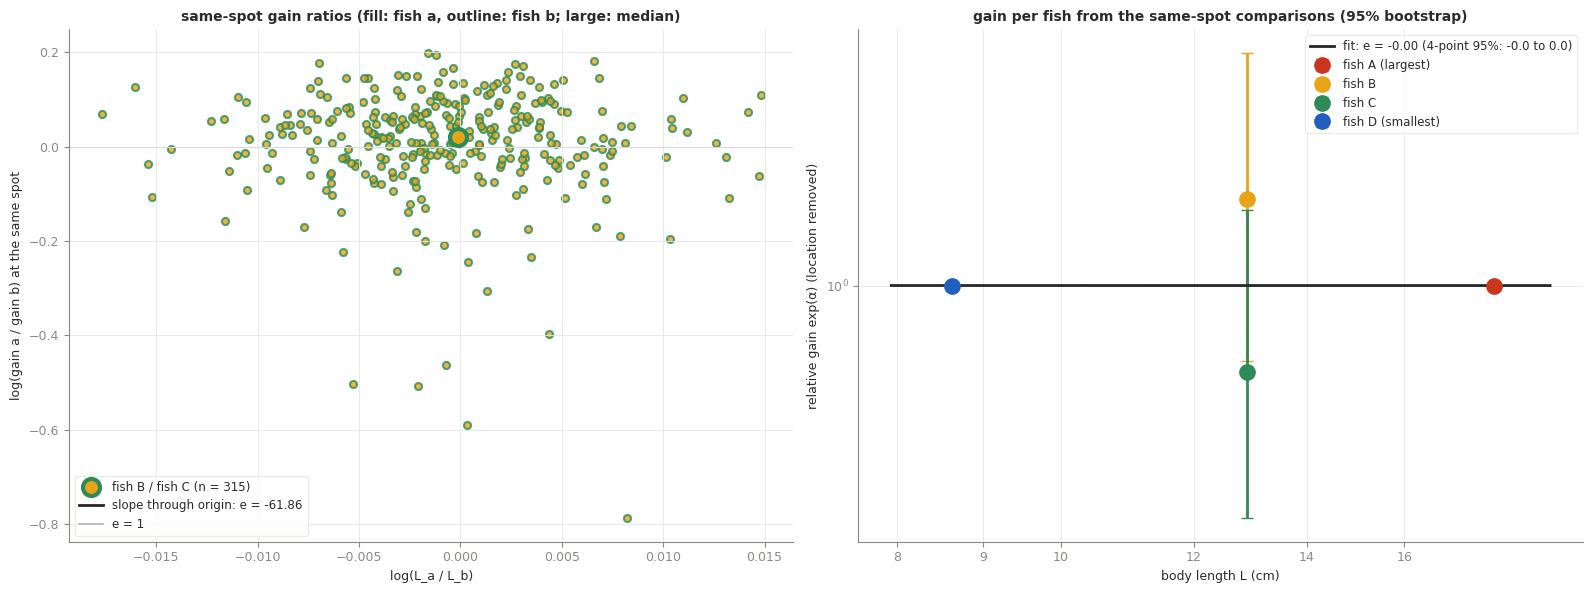

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
ax = axs[0]
for (fa, fb), g in MK.groupby(['fish_a', 'fish_b']):
    xj = g.log_L_ratio + rng.normal(0, 0.006, len(g))
    ax.scatter(xj, g.log_ratio, s=26, color=COLOR[fa], edgecolor=COLOR[fb], lw=1.5, alpha=0.8)
    ax.scatter(g.log_L_ratio.iloc[0], g.log_ratio.median(), s=150, color=COLOR[fa], edgecolor=COLOR[fb], lw=3, zorder=3,
               label=f'{NAME[fa]} / {NAME[fb]} (n = {len(g)})')
xx = np.linspace(0, MK.log_L_ratio.max() * 1.05, 20)
ax.plot(xx, slope0(MK) * xx, color='0.15', lw=2, label=f'slope through origin: e = {slope0(MK):.2f}')
ax.plot(xx, xx, color='0.7', lw=1.2, label='e = 1')
ax.axhline(0, color='0.85', lw=0.8)
ax.set(xlabel='log(L_a / L_b)', ylabel='log(gain a / gain b) at the same spot',
       title='same-spot gain ratios (fill: fish a, outline: fish b; large: median)')
ax.legend(fontsize=8.5, frameon=True, facecolor='white', edgecolor='#e6e6e3')
ax = axs[1]
for f in FISH:
    ax.errorbar(L_cm[f], REL.iloc[f, 1], yerr=[[REL.iloc[f, 1] - REL.iloc[f, 2]], [REL.iloc[f, 3] - REL.iloc[f, 1]]], fmt='o', ms=11,
                color=COLOR[f], mfc=COLOR[f], capsize=4, lw=2, label=NAME[f])
xx = np.linspace(L_cm.min() * 0.92, L_cm.max() * 1.08, 50)
ax.plot(xx, np.exp(e_fx.intercept) * (xx / Lref) ** e_fx.slope, color='0.15', lw=2,
        label=f'fit: e = {e_fx.slope:.2f} (4-point 95%: {SAME.iloc[1, 3]:.1f} to {SAME.iloc[1, 4]:.1f})')
ax.set(xscale='log', yscale='log', xlabel='body length L (cm)', ylabel='relative gain exp(α) (location removed)',
       title='gain per fish from the same-spot comparisons (95% bootstrap)')
ax.set_xticks([8, 9, 10, 12, 14, 16]); ax.set_xticklabels([8, 9, 10, 12, 14, 16]); ax.minorticks_off(); ax.grid(True, color='#e6e6e3')
ax.legend(fontsize=8.5, frameon=True, facecolor='white', edgecolor='#e6e6e3')
plt.tight_layout(); fig.savefig(f'{OUT}/figures/same_spot_gain_ratios.png', dpi=120); plt.show()